# Toy Simulations

We would like to show that our framework/method elegantly handles cases where surrogate model-based decision importances fail.
In particular, we consider toy multiverses that poke holes in how regression and random forests handle decision importances.

In [ ]:
# imports
import numpy as np
import pandas as pd
import itertools
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.inspection import permutation_importance
import sys
sys.path.append('../..')
from src.metrics.metrics import organize_multiverse_results, total_variance_decomposition_with_interactions

## Toy Multiverse #1
### Regression Predictions Fail
### RF Predictions Succeed; MDI Importances Fail; Permutation Importances Succeed

Interactions can cause linear regression models to fail both in prediction and interpretation, assuming that the interaction terms are not all included. If the interaction terms are all included, this can also lead to the case where `p=n`, so the regression will perfectly interpolate the data, but the model will have zero residual degrees of freedom, making statistical inference impossible (i.e. no standard errors or p-values can be calculated). Thus the only way around this problem is to know the interactions in advance, which is infeasible for large/complex multiverses.

Since random forests are ensembles of rule-based models, they handle the multiverses with a high amount of accuracy. In fact, if we set `bootstrap=False` (since we observe the full multiverse), then it will often get perfect predictive accuracy. However, MDI importances, which are the most popular form of tree-based importance, will fail. This is because for each possible initial split in a tree, each candidate feature yields a variance reduction of exactly 0.0, so the root node will get nothing. The tree is forced to arbitrarily pick one of the features to serve as the root node, and assuming it chooses `x1`, then `x1` will not receive any credit. However, if the researcher is savvy enough to know this is a potential issue, then permutation importance can be used and will sidestep this issue.

The multiverse is shown here:

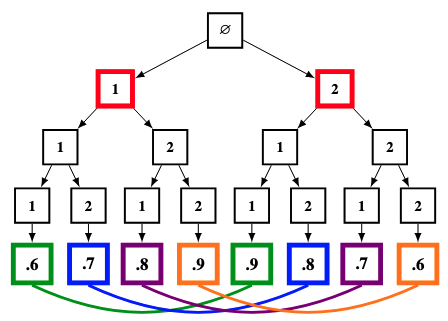

In [ ]:
# simple multiverse from Figure 7 in our paper draft (appendix)
x1 = [0, 0, 0, 1, 0, 1, 1, 1]
x2 = [0, 0, 1, 0, 1, 0, 1, 1]
x3 = [0, 1, 0, 0, 1, 1, 0, 1]
X = np.array([x1, x2, x3]).T
y = [0.6, 0.7, 0.8, 0.9, 0.9, 0.8, 0.7, 0.6]

In [ ]:
lm = LinearRegression()
lm.fit(X, y)
print('-- Coefficients --')
print(lm.coef_)
print('-- Intercept --')
print(lm.intercept_)
print('-- Metrics --')
print("Mean Squared Error: ", mean_squared_error(y, lm.predict(X)))
print("R^2 Score: ", r2_score(y, lm.predict(X)))
print('-- Predictions --')
print("Predictions: ", lm.predict(X))
print("Actual: ", y)

In [ ]:
# now fit a linear model that includes all interactions
poly = PolynomialFeatures(degree=3, interaction_only=True, include_bias=False)
X_poly = poly.fit_transform(X)
lm_poly = LinearRegression()
lm_poly.fit(X_poly, y)
print('-- Num. of Params --')
print("n =", X_poly.shape[0])
print("p =", X_poly.shape[1] + 1)  # +1 for the intercept
print('-- Coefficients --')
print(lm_poly.coef_)
print('-- Intercept --')
print(lm_poly.intercept_)
print('-- Metrics --')
print("Mean Squared Error: ", mean_squared_error(y, lm_poly.predict(X_poly)))
print("R^2 Score: ", r2_score(y, lm_poly.predict(X_poly)))
print('-- Predictions --')
print("Predictions: ", lm_poly.predict(X_poly))
print("Actual: ", y)

In [ ]:
# fit a random forest model
rf = RandomForestRegressor(n_estimators=100, random_state=42, bootstrap=False)
rf.fit(X, y)
print('-- MDI Importance --')
print(rf.feature_importances_)
print('\n-- Permutation Feature Importance --')
# we use n_repeats to shuffle the column multiple times and take the average drop in performance.
# we'll use negative MSE as the scoring metric so a bigger drop = higher importance.
pfi_results = permutation_importance(rf, X, y, n_repeats=50, random_state=42, scoring='neg_mean_squared_error')
for i, imp in enumerate(pfi_results.importances_mean):
    print(f"x{i+1}: {imp:.3f} (std: {pfi_results.importances_std[i]:.3f})")
print('-- Metrics --')
print("Mean Squared Error: ", mean_squared_error(y, rf.predict(X)))
print("R^2 Score: ", r2_score(y, rf.predict(X)))
print('-- Predictions --')
print("Predictions: ", rf.predict(X))
print("Actual: ", y)

## Toy Multiverse #2
### RF Predictions Work; Inference Doesn't

We find a toy scenario where using RFs as a surrogate model fails: when some sort of independent noise is included. In particular, we find that the bias of random forests towards features with high cardinality/entropy can be exploited in the case where the signal is not 'pure' to make the random forest believe that a completely non-informative feature is more important than the signal feature. Although the predictions of the RF are still accurate, both the MDI importances and permutation importances fail to identify the signal feature. We test this with RFs both with and without bootstrap to be sure to cover our bases. Issue is that this is just moving around the signal-to-noise ratio, which could of course mess up any method, including ours. Need to try with ours to ensure that we are slightly more robust.

In [ ]:
# Toy multiverse where only x1 matters. Feature x1 has a fixed effect of +0.05 on accuracy, while features x2 and x3 are pure noise.
# To break the applicability of the random forest, we consider the case where there is some random noise outside of the included judgment calls.
# This noise is independent from the features and is centered at zero, to properly reflect what measurement error could look like in a realistic natural sciences setting.

# define the categories for each decision
# signal feature (cardinality = 2)
x1_opts = [0, 1]
# noise feature (cardinality = 8)
x2_opts = [0, 1, 2, 3, 4, 5, 6, 7]
# noise feature (cardinality = 2)
x3_opts = [0, 1]

# generate the full multiverse (2 * 8 * 2 = 32 universes)
X = np.array(list(itertools.product(x1_opts, x2_opts, x3_opts)))

# generate y
# recall that x1 being 1 adds +0.05 to accuracy, while x2 and x3 do absolutely nothing
# we add random error to reflect possible measurement error that could occur in a real-world setting
np.random.seed(42)
noise = np.random.uniform(-0.05, 0.05, size=X.shape[0])  # uniform noise between -0.03 and 0.03
# noise = np.random.normal(0, 0.05, size=X.shape[0])  # mean 0, std dev 0.02
y = np.where(X[:, 0] == 1, 0.65, 0.60) + noise

In [ ]:
# random forest WITH bootstrap
rf = RandomForestRegressor(n_estimators=100, random_state=42, bootstrap=True)
rf.fit(X, y)
print("-- MDI Importances --")
print(f"x1 (signal feature): {rf.feature_importances_[0]:.3f}")
print(f"x2 (high cardinality noise feature): {rf.feature_importances_[1]:.3f}")
print(f"x3 (binary noise feature): {rf.feature_importances_[2]:.3f}")
print('-- Permutation Feature Importance --')
# we use n_repeats to shuffle the column multiple times and take the average drop in performance.
# we'll use negative MSE as the scoring metric so a bigger drop = higher importance.
pfi_results = permutation_importance(rf, X, y, n_repeats=50, random_state=42, scoring='neg_mean_squared_error')
for i, imp in enumerate(pfi_results.importances_mean):
    print(f"x{i+1}: {imp:.3f} (std: {pfi_results.importances_std[i]:.3f})")
print("-- Metrics --")
print("Mean Squared Error: ", mean_squared_error(y, rf.predict(X)))
print("R^2 Score: ", r2_score(y, rf.predict(X)))
print("-- Predictions --")
print("Predictions: ", rf.predict(X))
print("Actual: ", y)

In [ ]:
# now time for random forest WITH bootstrap
rf = RandomForestRegressor(n_estimators=100, random_state=42, bootstrap=False)
rf.fit(X, y)
print("-- MDI Importances --")
print(f"x1 (signal feature): {rf.feature_importances_[0]:.3f}")
print(f"x2 (high cardinality noise feature): {rf.feature_importances_[1]:.3f}")
print(f"x3 (binary noise feature): {rf.feature_importances_[2]:.3f}")
print('-- Permutation Feature Importance --')
# we use n_repeats to shuffle the column multiple times and take the average drop in performance.
# we'll use negative MSE as the scoring metric so a bigger drop = higher importance.
pfi_results = permutation_importance(rf, X, y, n_repeats=50, random_state=42, scoring='neg_mean_squared_error')
for i, imp in enumerate(pfi_results.importances_mean):
    print(f"x{i+1}: {imp:.3f} (std: {pfi_results.importances_std[i]:.3f})")
print("-- Metrics --")
print("Mean Squared Error: ", mean_squared_error(y, rf.predict(X)))
print("R^2 Score: ", r2_score(y, rf.predict(X)))
print("-- Predictions --")
print("Predictions: ", rf.predict(X))
print("Actual: ", y)